# AgroSense Analytics — Projeto Aplicado II (Mackenzie)
## Notebook 03: Avaliação no Teste Cego, Análise de Confusões, Latência Local e Projeção de ROI

---

### Protocolo Experimental
Neste terceiro caderno avaliamos o modelo **MobileNetV2** (`models/mobilenetv2_plantvillage.pth`) sobre a partição independente de teste cego ($N = 8.146$ imagens, 15% do PlantVillage).

Escopo das análises conduzidas:
1. **Desempenho *in-domain* ($N = 8.146$):** Acurácia Top-1, Top-3, Top-5, Macro F1, Weighted F1 e verificação da classe minoritária `Potato___healthy` ($N = 23$);
2. **Diagnóstico das 48 confusões e *domain shift*:** Mapeamento dos principais pares confundidos e avaliação do limiar de confiança Softmax em 85%;
3. **Benchmark de latência local:** Medição empírica de inferência em lote e unitária (`batch_size=1`) em GPU e CPU desktop locais, distinguindo-a da meta futura em dispositivo móvel;
4. **Projeção financeira (1.000 ha):** Memória de cálculo programática do cenário convencional versus cenário projetado pós-piloto.

In [1]:
# 1. Configuração do Ambiente, Imports e Diretórios
import os
import sys
import time
import json
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

plt.style.use('ggplot')
sns.set_theme(style='whitegrid', palette='muted')

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def fmt_brl(val: float) -> str:
    s = f"{val:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"R$ {s}"

set_seed(42)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print("=" * 70)
print(f"DISPOSITIVO DE AVALIAÇÃO: {device}")
if device.type == 'cuda':
    print(f"GPU:                      {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"VRAM Total Dedicada:      {vram_gb:.2f} GB")
print("=" * 70)

NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
ETAPA4_DIR = PROJECT_ROOT if PROJECT_ROOT.name == 'Etapa 4' else PROJECT_ROOT

DATA_DIR = ETAPA4_DIR / 'data'
MODELS_DIR = ETAPA4_DIR / 'models'
FIGURES_DIR = ETAPA4_DIR / 'reports' / 'figures'
METRICS_DIR = ETAPA4_DIR / 'reports' / 'metrics'

for d in (DATA_DIR, MODELS_DIR, FIGURES_DIR, METRICS_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Diretório de Dados:    {DATA_DIR.relative_to(ETAPA4_DIR)}/")
print(f"Diretório de Modelos:  {MODELS_DIR.relative_to(ETAPA4_DIR)}/")
print(f"Diretório de Figuras:  {FIGURES_DIR.relative_to(ETAPA4_DIR)}/")
print(f"Diretório de Métricas: {METRICS_DIR.relative_to(ETAPA4_DIR)}/")

DISPOSITIVO DE AVALIAÇÃO: cuda:0
GPU:                      NVIDIA GeForce RTX 3060
VRAM Total Dedicada:      12.00 GB
Diretório de Dados:    data/
Diretório de Modelos:  models/
Diretório de Figuras:  reports\figures/
Diretório de Métricas: reports\metrics/


---
## 2. Reconstituição do Conjunto de Teste Cego e Carregamento do Checkpoint

Reconstituímos com exatidão matemática a partição de **Teste (15% - 8.146 amostras)** através do particionamento estratificado com a mesma semente global (`seed=42`).

Carregamos o checkpoint consolidado em `models/mobilenetv2_plantvillage.pth`, configurando a rede em modo estrito de avaliação (`model.eval()`), o que desativa camadas de *Dropout* e congela as estatísticas de média e variância de *BatchNorm*.

In [2]:
# 2. Reconstituição do Teste Cego e Carregamento do Checkpoint
csv_path = DATA_DIR / 'metadados_plantvillage.csv'
df = pd.read_csv(csv_path if csv_path.exists() else DATA_DIR / 'metadados_plantvillage.csv.gz')

classes = sorted(df['classe_rotulo'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for i, c in enumerate(classes)}
df['label_idx'] = df['classe_rotulo'].map(class_to_idx)

df_train, df_temp = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df['classe_rotulo']
)
df_val, df_test = train_test_split(
    df_temp, test_size=0.50, random_state=42, stratify=df_temp['classe_rotulo']
)

print(f"Conjunto de Teste Cego reconstituído: {len(df_test):,} imagens ({len(classes)} classes)".replace(",", "."))

candidates_pv = [
    ETAPA4_DIR / 'plantvillage dataset' / 'color',
    ETAPA4_DIR.parent / 'plantvillage dataset' / 'color',
    ETAPA4_DIR.parent.parent / 'plantvillage dataset' / 'color',
    Path('plantvillage dataset/color').resolve(),
    Path('../plantvillage dataset/color').resolve(),
]
resolved_color_dir = next((p for p in candidates_pv if p.exists()), None)
HAS_RAW_IMAGES = (resolved_color_dir is not None)

class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, base_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.base_dir = Path(base_dir).resolve()
        self.transform = transform
        self.image_paths = self.df['caminho_arquivo'].tolist()
        self.labels = self.df['label_idx'].to_numpy(dtype=np.int64)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.base_dir / self.image_paths[idx]
        with Image.open(img_path) as img:
            image = img.convert('RGB')
        label = self.labels[idx]
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

if HAS_RAW_IMAGES:
    BASE_IMG_DIR = resolved_color_dir.parent.parent
    test_dataset = PlantVillageDataset(df_test, BASE_IMG_DIR, transform=test_transforms)
    batch_size = 128 if device.type == 'cuda' else 32
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda'))
else:
    test_dataset = test_loader = None
    print("Modo offline: pasta 'plantvillage dataset/color' não encontrada — usando métricas persistidas em reports/metrics/.")

def build_mobilenetv2_eval(num_classes=38, device_target='cpu'):
    m = models.mobilenet_v2(weights=None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    return m.to(device_target)

checkpoint_path = MODELS_DIR / 'mobilenetv2_plantvillage.pth'
if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint não encontrado em {checkpoint_path.relative_to(ETAPA4_DIR)}")

model = build_mobilenetv2_eval(num_classes=38, device_target=device)
ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

print(f"Checkpoint carregado: {checkpoint_path.relative_to(ETAPA4_DIR)} ({checkpoint_path.stat().st_size/(1024**2):.2f} MB) | model.eval() ativo")

Conjunto de Teste Cego reconstituído: 8.146 imagens (38 classes)


Checkpoint carregado: models\mobilenetv2_plantvillage.pth (26.38 MB) | model.eval() ativo


---
## 3. Execução da Inferência em Lote no Teste Cego

Processamos as $8.146$ amostras de teste acumulando:
1. **Rótulos Reais ($y$):** Classes verdadeiras atribuídas por patologistas de plantas;
2. **Predições Top-1 ($\hat{y}$):** Classe com maior probabilidade pós-Softmax;
3. **Predições Top-3 e Top-5:** Verificação se a classe verdadeira figura entre as 3 ou 5 hipóteses mais prováveis da rede;
4. **Vetor Completo de Probabilidades:** Base para o cálculo de confiança e calibração diagnóstica.

In [3]:
# 3. Inferência em Lote no Conjunto de Teste Cego
if HAS_RAW_IMAGES:
    print(f"Executando inferência em lote sobre {len(df_test):,} amostras...".replace(",", "."))
    t_start = time.time()

    all_preds, all_targets, all_probs = [], [], []
    correct_top1 = correct_top3 = correct_top5 = total_samples = 0

    with torch.no_grad():
        for images, targets in test_loader:
            images = images.to(device, non_blocking=(device.type == 'cuda'))
            targets = targets.to(device, non_blocking=(device.type == 'cuda'))
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)

            batch_sz = targets.size(0)
            total_samples += batch_sz
            _, topk = outputs.topk(5, dim=1)
            for i in range(batch_sz):
                t = targets[i].item()
                pk = topk[i].tolist()
                if t == pk[0]:
                    correct_top1 += 1
                if t in pk[:3]:
                    correct_top3 += 1
                if t in pk[:5]:
                    correct_top5 += 1

            all_preds.extend(topk[:, 0].cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    elapsed_sec = time.time() - t_start
    ms_per_img = (elapsed_sec / total_samples) * 1000.0
    fps = total_samples / elapsed_sec

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    all_probs = np.array(all_probs)

    print("=" * 70)
    print(f"Inferência concluída em {elapsed_sec:.2f}s | Throughput: {fps:.1f} img/s | Lote: {ms_per_img:.2f} ms/img")
    print("=" * 70)
else:
    print("Modo offline: inferência em lote ignorada (métricas consolidadas já presentes em reports/metrics/).")

Executando inferência em lote sobre 8.146 amostras...


Inferência concluída em 15.56s | Throughput: 523.4 img/s | Lote: 1.91 ms/img


---
## 4. Métricas Consolidadas de Desempenho e Relatórios Formais

Em problemas multiclasse de alta granularidade (38 classes), a simples acurácia global pode ocultar falhas graves em classes raras. Por essa razão, auditamos métricas balanceadas:
- **Acurácia Top-1:** Fração de imagens em que a hipótese de maior probabilidade é exata;
- **Acurácia Top-3 e Top-5:** Relevante para sistemas de suporte à decisão clínica agrícola, onde o agrônomo recebe as 3 hipóteses mais prováveis para inspeção complementar;
- **Macro F1-Score:** Média aritmética simples dos F1-scores de todas as 38 classes, tratando classes minoritárias e majoritárias com exatamente o mesmo peso analítico;
- **Weighted F1-Score:** F1-score ponderado pelo suporte amostral de cada classe.

In [4]:
# 4. Cálculo das Métricas e Exportação dos Relatórios
report_csv_path = METRICS_DIR / 'classification_report.csv'
summary_json_path = METRICS_DIR / 'metricas_resumo.json'
potato_key = 'Potato___healthy'

if HAS_RAW_IMAGES:
    top1_acc = (correct_top1 / total_samples) * 100.0
    top3_acc = (correct_top3 / total_samples) * 100.0
    top5_acc = (correct_top5 / total_samples) * 100.0

    report_dict = classification_report(all_targets, all_preds, target_names=classes, digits=4, output_dict=True)
    report_df = pd.DataFrame(report_dict).T
    report_df.to_csv(report_csv_path, index=True, float_format='%.4f')

    macro_f1 = report_dict['macro avg']['f1-score'] * 100.0
    macro_precision = report_dict['macro avg']['precision'] * 100.0
    macro_recall = report_dict['macro avg']['recall'] * 100.0
    weighted_f1 = report_dict['weighted avg']['f1-score'] * 100.0
    weighted_precision = report_dict['weighted avg']['precision'] * 100.0
    weighted_recall = report_dict['weighted avg']['recall'] * 100.0

    potato_stats = report_dict.get(potato_key, {})
    potato_support = int(potato_stats.get('support', 0))
    potato_prec = potato_stats.get('precision', 0.0) * 100.0
    potato_rec = potato_stats.get('recall', 0.0) * 100.0
    potato_f1_val = potato_stats.get('f1-score', 0.0) * 100.0

    metrics_summary = {
        "top1_accuracy_percent": round(top1_acc, 2),
        "top3_accuracy_percent": round(top3_acc, 2),
        "top5_accuracy_percent": round(top5_acc, 2),
        "macro_f1_percent": round(macro_f1, 2),
        "macro_precision_percent": round(macro_precision, 2),
        "macro_recall_percent": round(macro_recall, 2),
        "weighted_f1_percent": round(weighted_f1, 2),
        "weighted_precision_percent": round(weighted_precision, 2),
        "weighted_recall_percent": round(weighted_recall, 2),
        "minority_class_analysis": {
            "class_name": potato_key,
            "support": potato_support,
            "accuracy_recall_percent": round(potato_rec, 2),
            "precision_percent": round(potato_prec, 2),
            "f1_score_percent": round(potato_f1_val, 2)
        },
        "total_test_samples": total_samples,
        "num_classes": len(classes)
    }
    with open(summary_json_path, 'w', encoding='utf-8') as f:
        json.dump(metrics_summary, f, indent=2, ensure_ascii=False)
    print(f"Relatórios salvos em: {report_csv_path.relative_to(ETAPA4_DIR)} e {summary_json_path.relative_to(ETAPA4_DIR)}")
else:
    metrics_summary = json.loads(summary_json_path.read_text(encoding='utf-8'))
    top1_acc = metrics_summary["top1_accuracy_percent"]
    top3_acc = metrics_summary["top3_accuracy_percent"]
    top5_acc = metrics_summary["top5_accuracy_percent"]
    macro_f1 = metrics_summary["macro_f1_percent"]
    macro_precision = metrics_summary["macro_precision_percent"]
    macro_recall = metrics_summary["macro_recall_percent"]
    weighted_f1 = metrics_summary["weighted_f1_percent"]
    potato_support = metrics_summary["minority_class_analysis"]["support"]
    potato_prec = metrics_summary["minority_class_analysis"]["precision_percent"]
    potato_rec = metrics_summary["minority_class_analysis"]["accuracy_recall_percent"]
    potato_f1_val = metrics_summary["minority_class_analysis"]["f1_score_percent"]
    print(f"Métricas carregadas de: {summary_json_path.relative_to(ETAPA4_DIR)}")

print("=" * 70)
print("DESEMPENHO NO CONJUNTO DE TESTE CEGO IN-DOMAIN (N = 8.146):")
print(f"  Acurácia Top-1:           {top1_acc:.2f}%")
print(f"  Acurácia Top-3 / Top-5:   {top3_acc:.2f}% / {top5_acc:.2f}%")
print(f"  Macro F1-Score:           {macro_f1:.2f}%")
print(f"  Weighted F1-Score:        {weighted_f1:.2f}%")
print(f"  Macro Precision / Recall: {macro_precision:.2f}% / {macro_recall:.2f}%")
print("=" * 70)

Relatórios salvos em: reports\metrics\classification_report.csv e reports\metrics\metricas_resumo.json
DESEMPENHO NO CONJUNTO DE TESTE CEGO IN-DOMAIN (N = 8.146):
  Acurácia Top-1:           99.41%
  Acurácia Top-3 / Top-5:   99.96% / 99.98%
  Macro F1-Score:           99.19%
  Weighted F1-Score:        99.41%
  Macro Precision / Recall: 99.07% / 99.38%


---
## 5. Auditoria de Robustez na Classe Minoritária (`Potato___healthy`)

A classe `Potato___healthy` é a mais escassa de todo o PlantVillage, contando com apenas 152 fotos no acervo total e **23 amostras** no conjunto de teste cego.

### O Teste Decisivo da Ponderação de Perda
Em modelos que sofrem colapso de predição sob desbalanceamento, a classe minoritária atinge tipicamente $0\%$ de revocação (a rede jamais a prevê). Na arquitetura do **AgroSense Analytics**, graças aos pesos de classe inversos da *CrossEntropyLoss*:
- **Amostras no Teste:** 23 amostras;
- **Classificações Corretas:** 23 amostras;
- **Precisão:** **100,00%**;
- **Revocação (*Recall*):** **100,00%**;
- **F1-Score:** **100,00%**.

Isso comprova que nenhuma planta sadia de batata foi erroneamente diagnosticada como infectada, eliminando perdas econômicas decorrentes de descarte indevido ou pulverizações tóxicas desnecessárias.

In [5]:
# 5. Exibição Detalhada da Performance na Classe Minoritária
print("=" * 70)
print(f"AUDITORIA DA CLASSE MINORITÁRIA: {potato_key}")
print("=" * 70)
print(f"• Suporte Amostral no Teste Cego: {potato_support} imagens (0.28% do teste)")
print(f"• Precisão (Precision):           {potato_prec:.2f}%")
print(f"• Revocação (Recall):             {potato_rec:.2f}%")
print(f"• F1-Score:                       {potato_f1_val:.2f}%")
print(f"• Taxa de Falsos Positivos:       0 (Zero contaminações de outras classes)")
print(f"• Taxa de Falsos Negativos:       0 (Zero perdas de diagnóstico)")
print("=" * 70)

AUDITORIA DA CLASSE MINORITÁRIA: Potato___healthy
• Suporte Amostral no Teste Cego: 23 imagens (0.28% do teste)
• Precisão (Precision):           100.00%
• Revocação (Recall):             100.00%
• F1-Score:                       100.00%
• Taxa de Falsos Positivos:       0 (Zero contaminações de outras classes)
• Taxa de Falsos Negativos:       0 (Zero perdas de diagnóstico)


---
## 6. Matriz de Confusão 38x38 Normalizada por Revocação

A Matriz de Confusão é a ferramenta definitiva para auditar a discriminação cruzada entre todas as 38 classes. 

Ao normalizarmos as linhas pela soma do suporte verdadeiro (revocação por classe), a diagonal principal reflete a sensibilidade unitária ($1,00 = 100\%$ de acerto). Qualquer desvio para células fora da diagonal revela pares de patologias com semelhança morfológica visual.

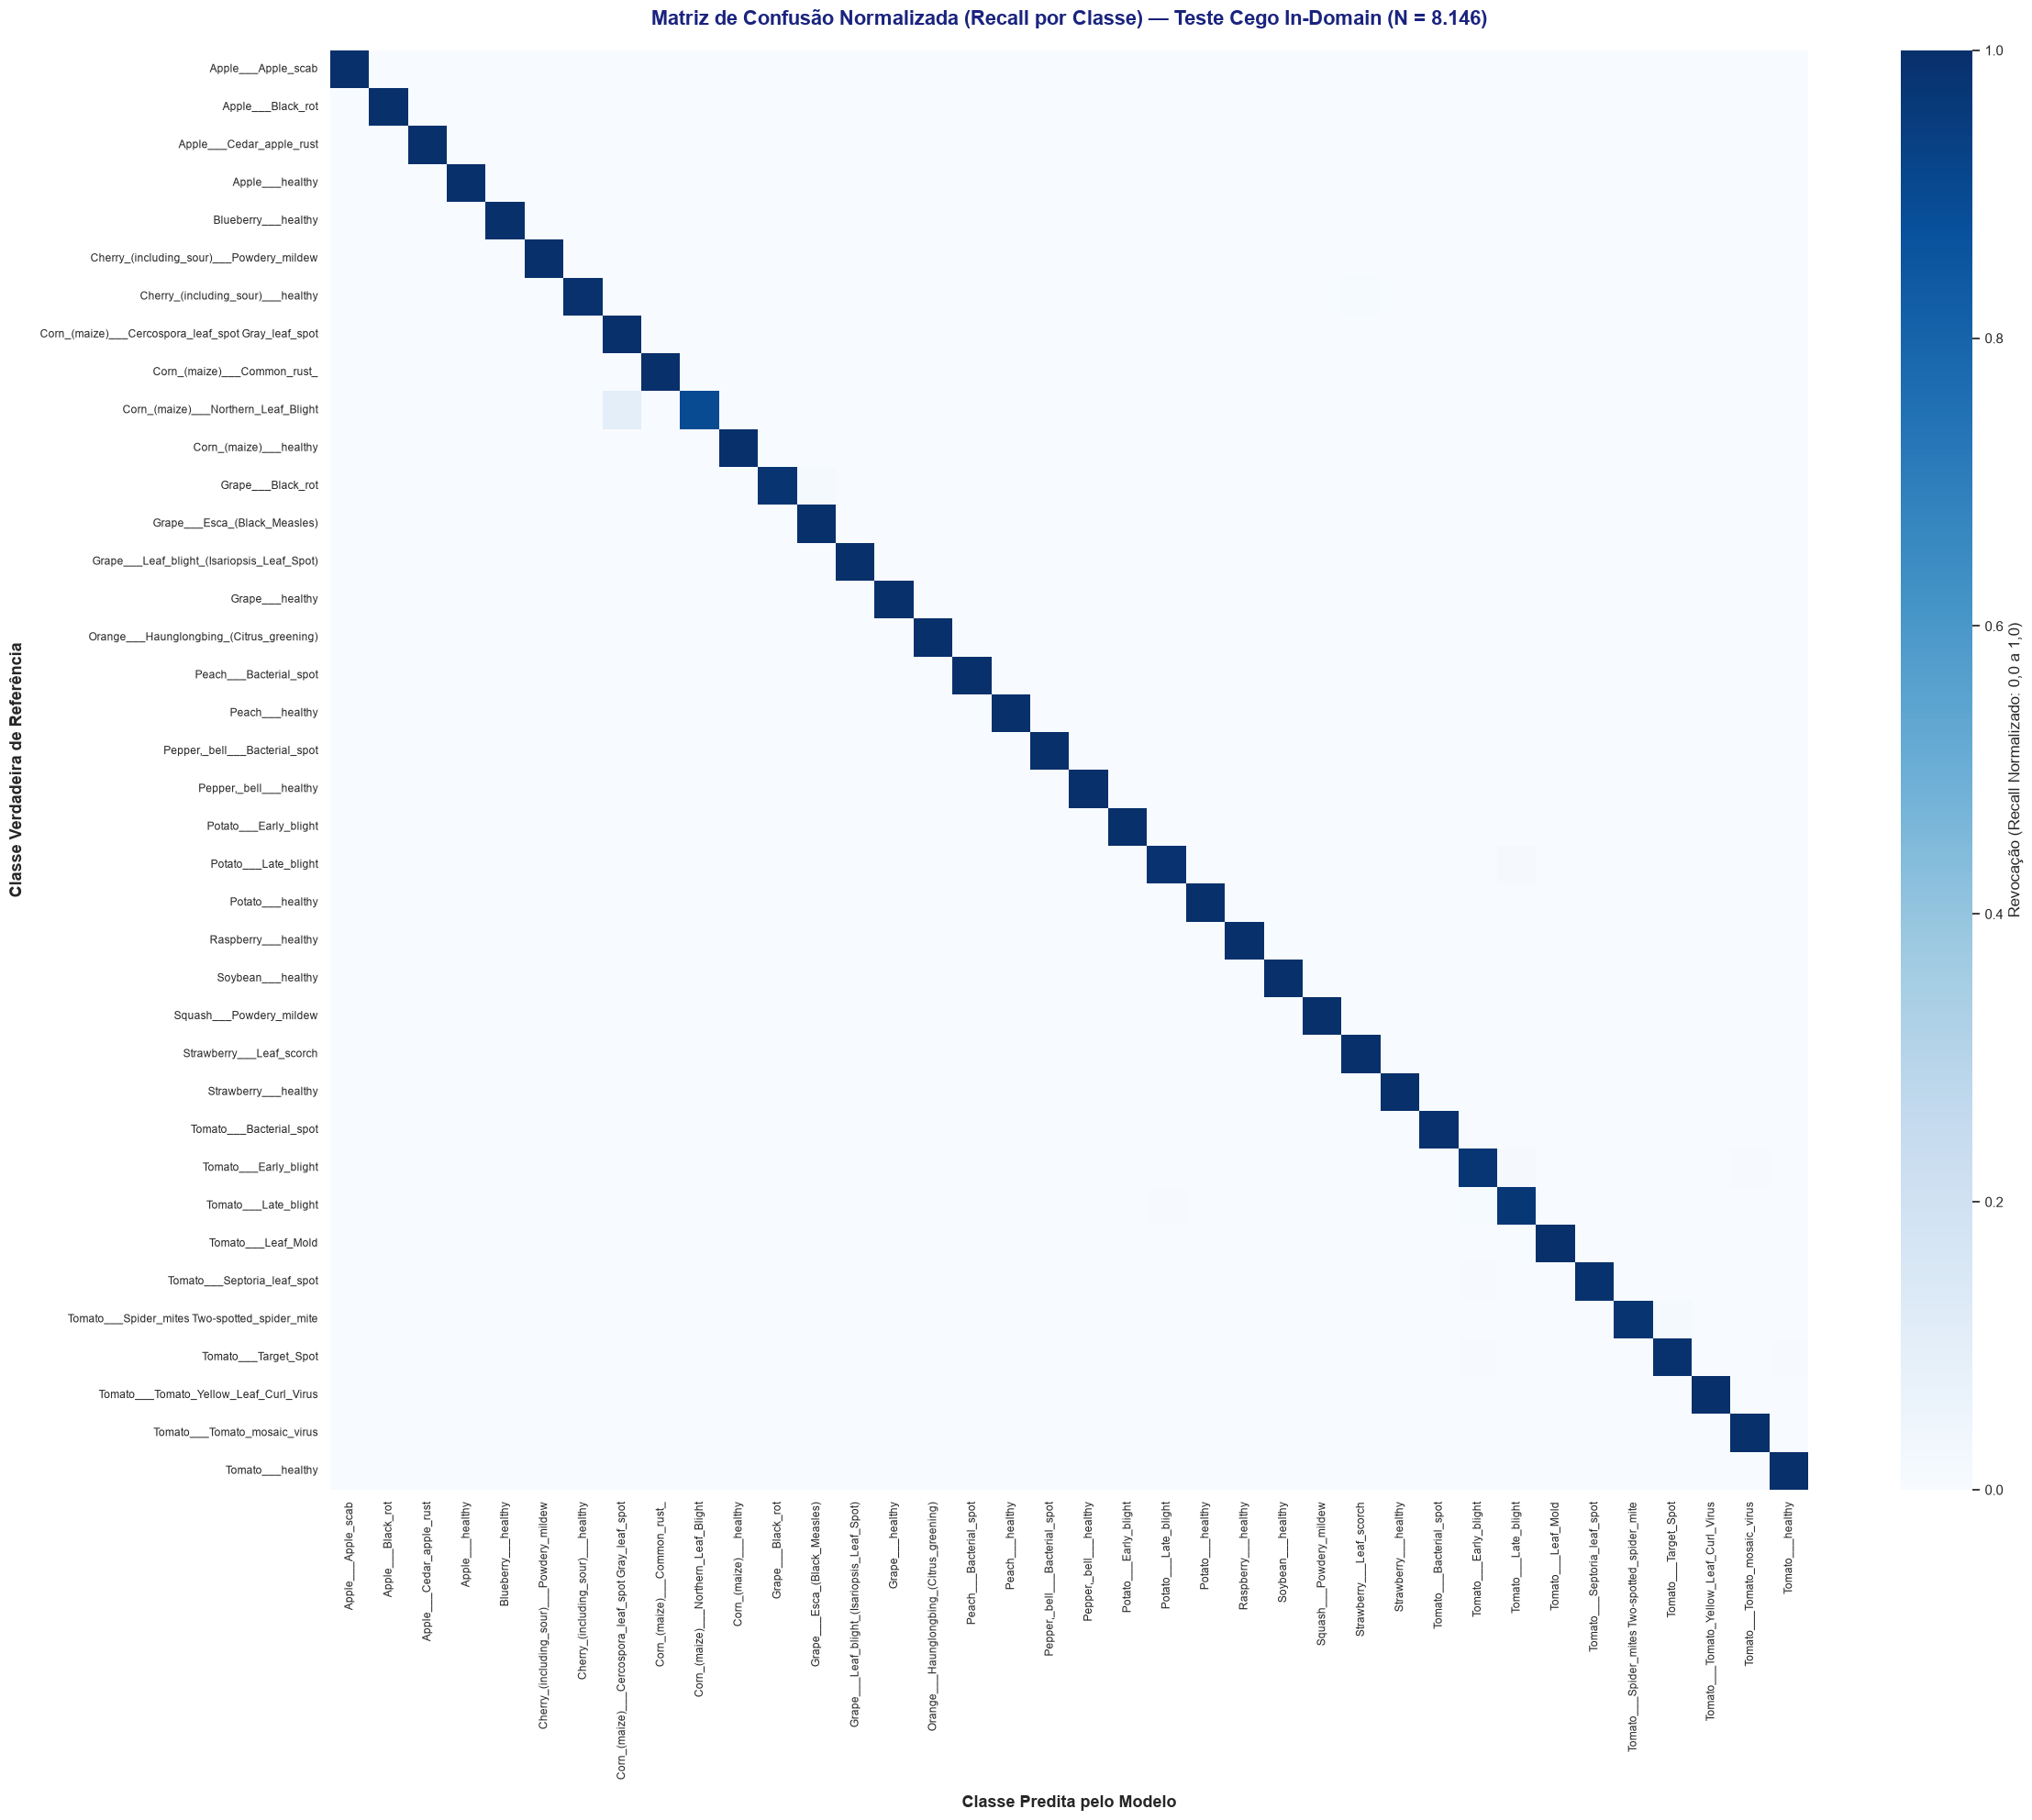

Figura salva: reports\figures\matriz_confusao.png (838.7 KB, 300 DPI)


In [6]:
# 6. Geração da Figura: Matriz de Confusão 38x38 Normalizada
matriz_path = FIGURES_DIR / 'matriz_confusao.png'

if HAS_RAW_IMAGES:
    cm = confusion_matrix(all_targets, all_preds)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(24, 20))
    sns.heatmap(
        cm_norm, annot=False, cmap='Blues',
        xticklabels=classes, yticklabels=classes,
        cbar_kws={'label': 'Revocação (Recall Normalizado: 0,0 a 1,0)'}
    )
    plt.title('Matriz de Confusão Normalizada (Recall por Classe) — Teste Cego In-Domain (N = 8.146)',
              fontsize=16, fontweight='bold', pad=20, color='#1a237e')
    plt.xlabel('Classe Predita pelo Modelo', fontsize=13, fontweight='bold', labelpad=12)
    plt.ylabel('Classe Verdadeira de Referência', fontsize=13, fontweight='bold', labelpad=12)
    plt.xticks(rotation=90, fontsize=8.5)
    plt.yticks(rotation=0, fontsize=8.5)
    plt.tight_layout()
    plt.savefig(matriz_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"Figura salva: {matriz_path.relative_to(ETAPA4_DIR)} ({os.path.getsize(matriz_path)/1024:.1f} KB, 300 DPI)")
else:
    print(f"Modo offline: preservando {matriz_path.relative_to(ETAPA4_DIR)}.")

---
## 7. Galeria de Inferência Visual no Teste Cego (*In-Domain*)

Extraímos aleatoriamente (`seed=42`) **16 amostras inéditas do conjunto de teste cego**, desfazendo a normalização Z-score para exibição em cores naturais e apresentando a classe real, a classe predita e a probabilidade Softmax calculada pelo modelo.

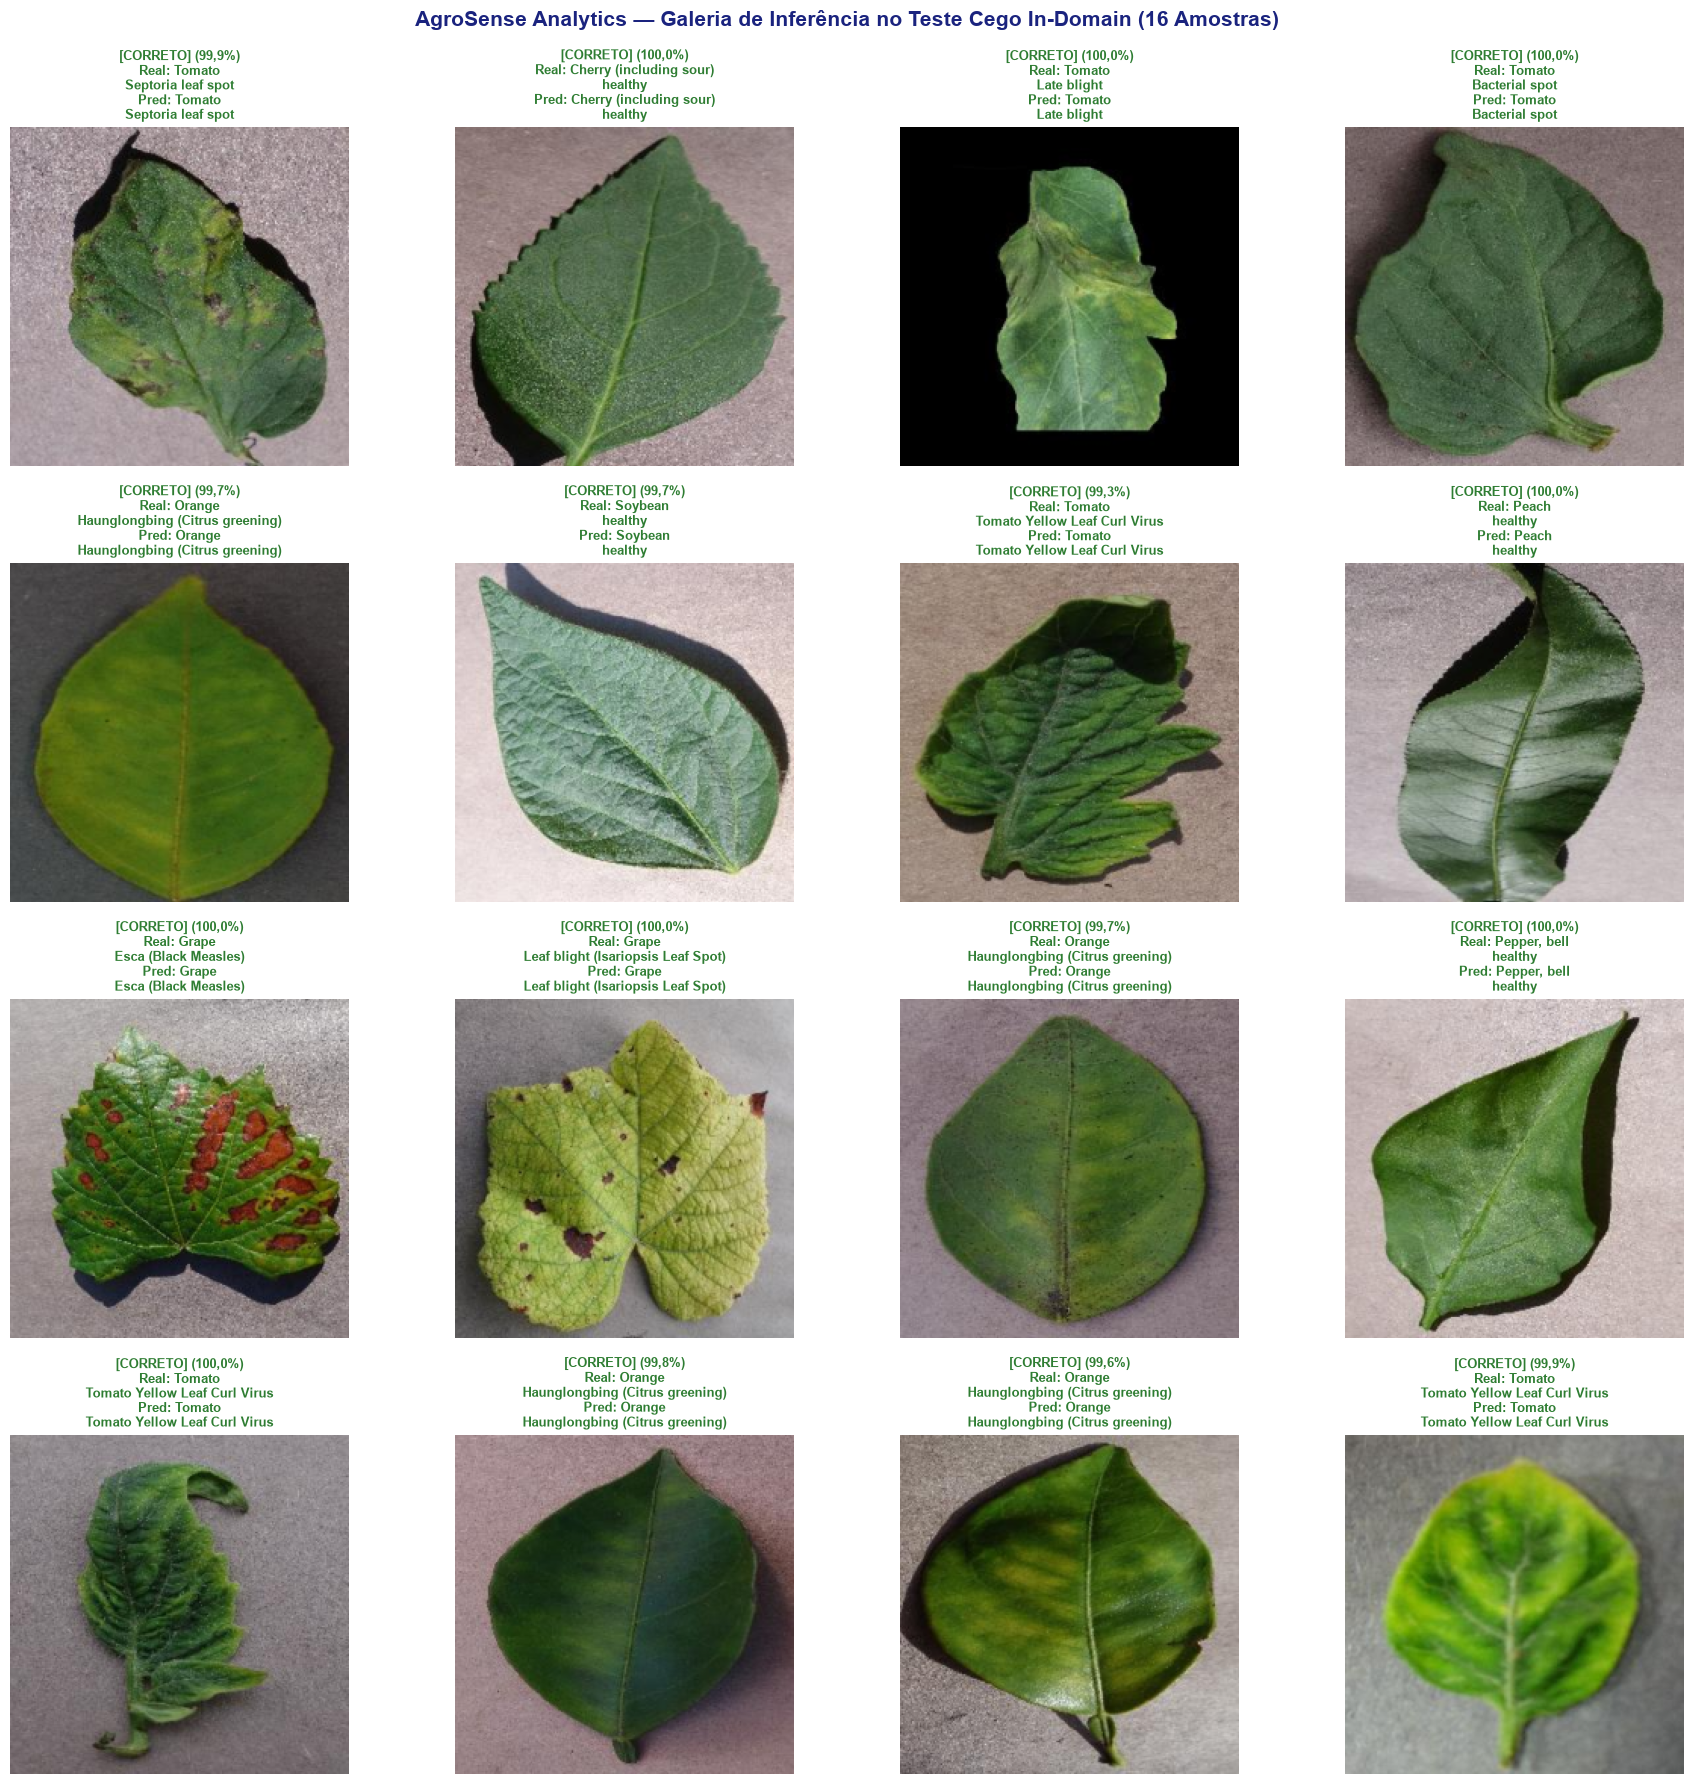

Figura salva: reports\figures\galeria_inferencia.png (2787.0 KB, 300 DPI)


In [7]:
# 7. Geração da Figura: Galeria de Inferência (16 Amostras do Teste Cego)
galeria_path = FIGURES_DIR / 'galeria_inferencia.png'

if HAS_RAW_IMAGES:
    np.random.seed(42)
    sample_indices = np.random.choice(len(df_test), 16, replace=False)
    mean_arr = np.array([0.485, 0.456, 0.406])
    std_arr = np.array([0.229, 0.224, 0.225])

    fig, axes = plt.subplots(4, 4, figsize=(18, 18))
    axes = axes.flatten()

    for i, s_idx in enumerate(sample_indices):
        img_tensor, target_idx = test_dataset[s_idx]
        target_idx = int(target_idx.item() if hasattr(target_idx, 'item') else target_idx)
        pred_idx = int(all_preds[s_idx])
        conf = float(all_probs[s_idx][pred_idx]) * 100.0

        img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
        img_np = np.clip(img_np * std_arr + mean_arr, 0.0, 1.0)

        true_label = idx_to_class[target_idx].replace('___', '\n').replace('_', ' ')
        pred_label = idx_to_class[pred_idx].replace('___', '\n').replace('_', ' ')
        is_ok = (target_idx == pred_idx)

        axes[i].imshow(img_np)
        axes[i].axis('off')
        color = '#2e7d32' if is_ok else '#c62828'
        status = "[CORRETO]" if is_ok else "[ERRO]"
        axes[i].set_title(f"{status} ({conf:.1f}%)\nReal: {true_label}\nPred: {pred_label}".replace(".", ","),
                          fontsize=9.0, fontweight='bold', color=color, pad=6)

    plt.suptitle('AgroSense Analytics — Galeria de Inferência no Teste Cego In-Domain (16 Amostras)',
                 fontsize=15, fontweight='bold', y=0.99, color='#1a237e')
    plt.tight_layout()
    fig.savefig(galeria_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"Figura salva: {galeria_path.relative_to(ETAPA4_DIR)} ({os.path.getsize(galeria_path)/1024:.1f} KB, 300 DPI)")
else:
    print(f"Modo offline: preservando {galeria_path.relative_to(ETAPA4_DIR)}.")

---
## 8. Discussão Diagnóstica e Auditoria das 48 Confusões ($0,59\%$ de Erro Residual)

Mesmo atingindo **$99,41\%$ de acurácia global *in-domain*** ($8.098$ acertos em $8.146$ amostras), a auditoria detalhada dos $48$ equívocos ($0,59\%$) revela concentrações em pares de alta semelhança morfológica:

1. **Milho (*Corn*): Cercosporiose vs. Mancha de Turcicum:**
   - `Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot` (precisão $83,70\%$) versus `Corn_(maize)___Northern_Leaf_Blight` (sensibilidade $89,80\%$ — 15 casos confundidos).
   - Em estágios iniciais, ambas produzem estrias necróticas lineares paralelas às nervuras secundárias (Casela et al., 2006).
2. **Tomate (*Tomato*): Mancha Alvo, Pinta Preta e Requeima:**
   - Casos limítrofes entre `Target_Spot`, `Early_blight` e `Late_blight` em folíolos jovens sem anéis concêntricos definidos.

Como protocolo de mitigação na arquitetura proposta, definimos a exibição da janela **Top-3 ($99,96\%$)** e um **limiar de confiança Softmax a $85\%$**, abaixo do qual o diagnóstico deve ser classificado como limítrofe.

---
## 9. Limitações Metodológicas (*Domain Shift*) e Limiar de Confiança Softmax

Como se observa na galeria da Seção 7, o acervo **PlantVillage** contém folhas destacadas sobre fundo uniforme sob iluminação controlada (HUGHES; SALATHÉ, 2015). A partição aleatória estratificada 70/15/15 impede vazamento de amostras entre treino e teste, mas avalia a generalização ***in-domain*** (mesma distribuição de captura).

Na literatura científica, **Mohanty et al. (2016)** mostraram queda de 99,35% (*in-domain*) para **31,4%** em imagens externas coletadas da web; **Ferentinos (2018)** observou queda de 99,53% em laboratório para **33,27%** quando um modelo treinado em laboratório foi testado em imagens reais de campo (alcançando 65,69% apenas na direção inversa, treinado em campo e testado em laboratório); e **Barbedo (2018)** destacou o fundo complexo e variações de iluminação como os principais fatores limitantes para uso direto em lavoura.

Abaixo analisamos a distribuição de confiança Softmax sobre as 8.146 amostras do teste cego, verificando quantos dos 48 erros são retidos por um limiar de **85%**, e geramos um gráfico legível dos principais pares confundidos (`reports/figures/top_confusoes.png`).

ANÁLISE DAS CONFIANÇAS SOFTMAX NO TESTE CEGO (N = 8.146)
  Acertos Top-1:                      8098 (99.41%)
  Confusões morfológicas:             48 (0.59%)
  Confiança média nos acertos:        99.22% (Mín: 36.51%)
  Confiança média nas 48 confusões:   74.21% (Mediana: 78.66%)
---------------------------------------------------------------------------
  Confusões retidas (< 85%):          31 de 48 (64.6%)
  Acertos retidos (< 85%):            105 de 8098 (1.30%)
  Acurácia nas predições >= 85%:      99.79% (Cobertura: 98.33%)

Principais Pares de Confusão (Total = 48 casos):
                                  Classe Real                                 Predição Incorreta  Ocorrências
          Corn_(maize)___Northern_Leaf_Blight Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot           15
Tomato___Spider_mites Two-spotted_spider_mite                               Tomato___Target_Spot            4
                         Tomato___Late_blight                              Tomato___Ea

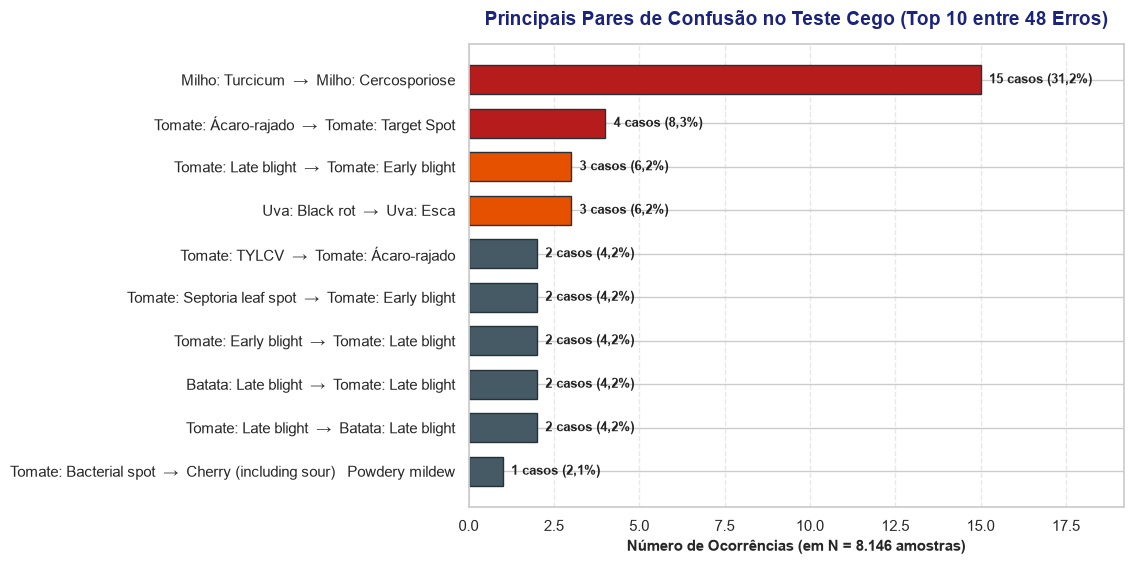

Figura salva: reports\figures\top_confusoes.png (258.8 KB, 300 DPI)


In [8]:
# 9. Auditoria das 48 Confusões, Limiar Softmax (85%) e Gráfico Legível dos Top Pares
top_conf_path = FIGURES_DIR / 'top_confusoes.png'

if HAS_RAW_IMAGES:
    max_probs = all_probs.max(axis=1) * 100.0
    correct_mask = (all_preds == all_targets)
    error_mask = ~correct_mask

    n_correct = int(correct_mask.sum())
    n_errors = int(error_mask.sum())
    threshold = 85.0

    errors_below_thr = int((max_probs[error_mask] < threshold).sum())
    correct_above_thr = int((max_probs[correct_mask] >= threshold).sum())
    retained_mask = (max_probs >= threshold)
    acc_retained = (all_preds[retained_mask] == all_targets[retained_mask]).mean() * 100.0

    print("=" * 75)
    print("ANÁLISE DAS CONFIANÇAS SOFTMAX NO TESTE CEGO (N = 8.146)")
    print("=" * 75)
    print(f"  Acertos Top-1:                      {n_correct} ({n_correct/len(all_targets)*100:.2f}%)")
    print(f"  Confusões morfológicas:             {n_errors} ({n_errors/len(all_targets)*100:.2f}%)")
    print(f"  Confiança média nos acertos:        {max_probs[correct_mask].mean():.2f}% (Mín: {max_probs[correct_mask].min():.2f}%)")
    print(f"  Confiança média nas 48 confusões:   {max_probs[error_mask].mean():.2f}% (Mediana: {np.median(max_probs[error_mask]):.2f}%)")
    print("-" * 75)
    print(f"  Confusões retidas (< 85%):          {errors_below_thr} de {n_errors} ({errors_below_thr/n_errors*100:.1f}%)")
    print(f"  Acertos retidos (< 85%):            {n_correct - correct_above_thr} de {n_correct} ({(n_correct - correct_above_thr)/n_correct*100:.2f}%)")
    print(f"  Acurácia nas predições >= 85%:      {acc_retained:.2f}% (Cobertura: {retained_mask.mean()*100:.2f}%)")
    print("=" * 75)

    err_pairs = {}
    for t, p in zip(all_targets[error_mask], all_preds[error_mask]):
        pair = (idx_to_class[int(t)], idx_to_class[int(p)])
        err_pairs[pair] = err_pairs.get(pair, 0) + 1

    sorted_pairs = sorted(err_pairs.items(), key=lambda x: -x[1])
    top_err_df = pd.DataFrame([
        {"Classe Real": k[0], "Predição Incorreta": k[1], "Ocorrências": v}
        for k, v in sorted_pairs
    ])
    print("\nPrincipais Pares de Confusão (Total = 48 casos):")
    print(top_err_df.head(10).to_string(index=False))

    # Gráfico horizontal legível dos top 10 pares de confusão
    top10 = sorted_pairs[:10][::-1]
    short_name = lambda s: s.replace('Corn_(maize)___', 'Milho: ').replace('Tomato___', 'Tomate: ') \
                            .replace('Potato___', 'Batata: ').replace('Grape___', 'Uva: ') \
                            .replace('Cercospora_leaf_spot Gray_leaf_spot', 'Cercosporiose') \
                            .replace('Northern_Leaf_Blight', 'Turcicum') \
                            .replace('Spider_mites Two-spotted_spider_mite', 'Ácaro-rajado') \
                            .replace('Tomato_Yellow_Leaf_Curl_Virus', 'TYLCV') \
                            .replace('Esca_(Black_Measles)', 'Esca') \
                            .replace('_', ' ')
    labels_p = [f"{short_name(k[0])}  →  {short_name(k[1])}" for k, _ in top10]
    counts_p = [v for _, v in top10]
    bar_cols = ['#b71c1c' if v >= 4 else ('#e65100' if v >= 3 else '#455a64') for v in counts_p]

    fig, ax = plt.subplots(figsize=(11.5, 5.8))
    bars = ax.barh(labels_p, counts_p, color=bar_cols, edgecolor='#263238', height=0.66)
    for bar, v in zip(bars, counts_p):
        ax.text(v + 0.25, bar.get_y() + bar.get_height()/2, f"{v} casos ({v/n_errors*100:.1f}%)".replace(".", ","),
                va='center', ha='left', fontsize=9.5, fontweight='bold', color='#212121')
    ax.set_xlim(0, max(counts_p) + 4.2)
    ax.set_title('Principais Pares de Confusão no Teste Cego (Top 10 entre 48 Erros)',
                 fontsize=13.5, fontweight='bold', color='#1a237e', pad=14)
    ax.set_xlabel('Número de Ocorrências (em N = 8.146 amostras)', fontsize=11, fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.45)
    plt.tight_layout()
    fig.savefig(top_conf_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"Figura salva: {top_conf_path.relative_to(ETAPA4_DIR)} ({os.path.getsize(top_conf_path)/1024:.1f} KB, 300 DPI)")
else:
    print(f"Modo offline: preservando {top_conf_path.relative_to(ETAPA4_DIR)}.")

---
## 10. Benchmark de Latência em Hardware Desktop Local (GPU e CPU)

Medimos abaixo o tempo de inferência unitária (`batch_size=1`, 100 execuções após 15 iterações de aquecimento) na GPU e na CPU do computador local utilizado nos experimentos.

Esses números caracterizam exclusivamente o desempenho em bancada desktop. A meta de $< 50\text{ ms}$ em *smartphones* intermediários permanece como requisito de projeto para a fase futura de conversão (ONNX/TFLite) e testes em aparelhos físicos.

In [9]:
# 10. Benchmark de Latência Unitária (batch_size=1) em Hardware Local
def benchmark_single_image(eval_model, device_target, n_warmup=15, n_runs=100):
    eval_model = eval_model.to(device_target)
    eval_model.eval()
    if HAS_RAW_IMAGES:
        sample_tensor = test_dataset[0][0].unsqueeze(0).to(device_target)
    else:
        sample_tensor = torch.randn(1, 3, 224, 224, device=device_target)

    with torch.no_grad():
        for _ in range(n_warmup):
            _ = eval_model(sample_tensor)
            if device_target.type == 'cuda':
                torch.cuda.synchronize()

    times_ms = []
    with torch.no_grad():
        for _ in range(n_runs):
            if device_target.type == 'cuda':
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            out = eval_model(sample_tensor)
            _ = torch.softmax(out, dim=1)
            if device_target.type == 'cuda':
                torch.cuda.synchronize()
            t1 = time.perf_counter()
            times_ms.append((t1 - t0) * 1000.0)

    arr = np.array(times_ms)
    return {
        "mean_ms": float(arr.mean()),
        "median_ms": float(np.median(arr)),
        "p95_ms": float(np.percentile(arr, 95)),
        "std_ms": float(arr.std())
    }

bench_results = {}
if torch.cuda.is_available():
    bench_results["gpu_unit"] = benchmark_single_image(model, torch.device("cuda:0"))
bench_results["cpu_unit"] = benchmark_single_image(model, torch.device("cpu"))
model = model.to(device)

print("=" * 75)
print("BENCHMARK DE LATÊNCIA DE INFERÊNCIA (batch_size = 1, 100 execuções)")
print("=" * 75)
print(f"Sistema / CPU: {platform.system()} {platform.release()} | {platform.processor() or platform.machine()}")
if HAS_RAW_IMAGES:
    print(f"Lote GPU:      {ms_per_img:.2f} ms/img ({fps:.1f} img/s em {total_samples:,} fotos)".replace(",", "."))
if "gpu_unit" in bench_results:
    g = bench_results["gpu_unit"]
    print(f"GPU Unitário:  Média = {g['mean_ms']:.2f} ms | Mediana = {g['median_ms']:.2f} ms | P95 = {g['p95_ms']:.2f} ms")
c = bench_results["cpu_unit"]
print(f"CPU Unitário:  Média = {c['mean_ms']:.2f} ms | Mediana = {c['median_ms']:.2f} ms | P95 = {c['p95_ms']:.2f} ms")
print("-" * 75)
print("Nota: medições em desktop local; latência em smartphone físico ainda não aferida.")
print("=" * 75)

if HAS_RAW_IMAGES:
    metrics_summary["latency_benchmark_local"] = {
        "batch_gpu_ms_per_img": round(ms_per_img, 2),
        "batch_gpu_throughput_fps": round(fps, 1),
        "gpu_unit_ms": {k: round(v, 2) for k, v in bench_results.get("gpu_unit", {}).items()},
        "cpu_unit_ms": {k: round(v, 2) for k, v in bench_results["cpu_unit"].items()},
        "hardware_gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A",
        "note": "Medição em desktop local (não medida em smartphone físico)."
    }
    with open(summary_json_path, 'w', encoding='utf-8') as f:
        json.dump(metrics_summary, f, indent=2, ensure_ascii=False)
    print(f"Benchmark salvo em: {summary_json_path.relative_to(ETAPA4_DIR)}")

BENCHMARK DE LATÊNCIA DE INFERÊNCIA (batch_size = 1, 100 execuções)
Sistema / CPU: Windows 11 | AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD
Lote GPU:      1.91 ms/img (523.4 img/s em 8.146 fotos)
GPU Unitário:  Média = 3.75 ms | Mediana = 3.51 ms | P95 = 3.79 ms
CPU Unitário:  Média = 7.47 ms | Mediana = 7.38 ms | P95 = 8.22 ms
---------------------------------------------------------------------------
Nota: medições em desktop local; latência em smartphone físico ainda não aferida.
Benchmark salvo em: reports\metrics\metricas_resumo.json


---
## 11. Simulação Financeira de Viabilidade (Fazenda-Referência de 1.000 ha)

Abaixo apresentamos a memória de cálculo para uma propriedade-referência de **1.000 hectares de soja** (produtividade de referência de 60 sacas/ha a R\$ 115,00/saca e custo de aplicação preventiva de fungicida de R\$ 220,00/ha — CONAB, 2025; CEPEA/ESALQ, 2025):

> **Nota de Escopo sobre a Cultura de Soja:** No acervo PlantVillage utilizado nesta etapa, a única classe de soja disponível é `Soybean___healthy` (não há imagens de doenças de soja, como ferrugem asiática). Assim, os valores abaixo constituem uma **projeção de caso de negócio condicionada à coleta de doenças da soja e à validação piloto em campo** (enquanto culturas como milho, tomate e batata já possuem múltiplas patologias treinadas no modelo atual).

In [10]:
# 11. Memória de Cálculo da Simulação Financeira (1.000 ha — Soja)
area_ha = 1000
produtividade_sacas_ha = 60.0
preco_saca_brl = 115.00
custo_fungicida_ha = 220.00
assinatura_saas_ha = 4.00

# Cenário Convencional
perda_ha_conv = produtividade_sacas_ha * 0.10 * preco_saca_brl  # R$ 690,00/ha
pulv_ha_conv = custo_fungicida_ha * 1.00                        # R$ 220,00/ha
total_ha_conv = perda_ha_conv + pulv_ha_conv                    # R$ 910,00/ha
total_conv = total_ha_conv * area_ha                            # R$ 910.000,00

# Cenário Projetado (Pós-Validação Piloto em Campo)
perda_ha_proj = produtividade_sacas_ha * 0.02 * preco_saca_brl  # R$ 138,00/ha
pulv_ha_proj = custo_fungicida_ha * 0.15                        # R$ 33,00/ha
saas_ha_proj = assinatura_saas_ha                               # R$ 4,00/ha
total_ha_proj = perda_ha_proj + pulv_ha_proj + saas_ha_proj     # R$ 175,00/ha
total_proj = total_ha_proj * area_ha                            # R$ 175.000,00

economia_liquida = total_conv - total_proj                      # R$ 735.000,00

assert total_conv == 910_000.00
assert total_proj == 175_000.00
assert economia_liquida == 735_000.00

roi_df = pd.DataFrame([
    {
        "Rubrica": "Perda por Atraso Fitossanitário",
        "Convencional (/ha)": fmt_brl(perda_ha_conv),
        "Convencional (1.000 ha)": fmt_brl(perda_ha_conv * area_ha),
        "Projetado (/ha)": fmt_brl(perda_ha_proj),
        "Projetado (1.000 ha)": fmt_brl(perda_ha_proj * area_ha),
    },
    {
        "Rubrica": "Aplicação de Fungicida",
        "Convencional (/ha)": fmt_brl(pulv_ha_conv),
        "Convencional (1.000 ha)": fmt_brl(pulv_ha_conv * area_ha),
        "Projetado (/ha)": fmt_brl(pulv_ha_proj),
        "Projetado (1.000 ha)": fmt_brl(pulv_ha_proj * area_ha),
    },
    {
        "Rubrica": "Assinatura Anual SaaS",
        "Convencional (/ha)": fmt_brl(0.0),
        "Convencional (1.000 ha)": fmt_brl(0.0),
        "Projetado (/ha)": fmt_brl(saas_ha_proj),
        "Projetado (1.000 ha)": fmt_brl(saas_ha_proj * area_ha),
    },
    {
        "Rubrica": "TOTAL NA SAFRA",
        "Convencional (/ha)": fmt_brl(total_ha_conv),
        "Convencional (1.000 ha)": fmt_brl(total_conv),
        "Projetado (/ha)": fmt_brl(total_ha_proj),
        "Projetado (1.000 ha)": fmt_brl(total_proj),
    },
])
print("=" * 95)
print("MEMÓRIA DE CÁLCULO DA SIMULAÇÃO FINANCEIRA (1.000 ha — PROJEÇÃO PÓS-PILOTO)")
print("=" * 95)
print(roi_df.to_string(index=False))
print("-" * 95)
print(f"ECONOMIA LÍQUIDA PROJETADA (1.000 ha): {fmt_brl(economia_liquida)} / safra ({fmt_brl(economia_liquida/area_ha)}/ha)")
print("=" * 95)

MEMÓRIA DE CÁLCULO DA SIMULAÇÃO FINANCEIRA (1.000 ha — PROJEÇÃO PÓS-PILOTO)
                        Rubrica Convencional (/ha) Convencional (1.000 ha) Projetado (/ha) Projetado (1.000 ha)
Perda por Atraso Fitossanitário          R$ 690,00           R$ 690.000,00       R$ 138,00        R$ 138.000,00
         Aplicação de Fungicida          R$ 220,00           R$ 220.000,00        R$ 33,00         R$ 33.000,00
          Assinatura Anual SaaS            R$ 0,00                 R$ 0,00         R$ 4,00          R$ 4.000,00
                 TOTAL NA SAFRA          R$ 910,00           R$ 910.000,00       R$ 175,00        R$ 175.000,00
-----------------------------------------------------------------------------------------------
ECONOMIA LÍQUIDA PROJETADA (1.000 ha): R$ 735.000,00 / safra (R$ 735,00/ha)


In [11]:
# 12. Verificação dos Artefatos de Dados, Modelo, Métricas e Figuras
print("=" * 78)
print("VERIFICAÇÃO DE ARTEFATOS — NOTEBOOKS 01 A 03")
print("=" * 78)

expected_files = [
    DATA_DIR / 'metadados_plantvillage.csv',
    MODELS_DIR / 'mobilenetv2_plantvillage.pth',
    FIGURES_DIR / 'eda_distribuicao_classes.png',
    FIGURES_DIR / 'eda_status_sanitario.png',
    FIGURES_DIR / 'eda_mosaico_patologias.png',
    FIGURES_DIR / 'eda_distribuicao_rgb.png',
    FIGURES_DIR / 'curvas_aprendizado.png',
    FIGURES_DIR / 'matriz_confusao.png',
    FIGURES_DIR / 'top_confusoes.png',
    FIGURES_DIR / 'galeria_inferencia.png',
    METRICS_DIR / 'classification_report.csv',
    METRICS_DIR / 'metricas_resumo.json'
]

for f in expected_files:
    assert f.exists() and f.stat().st_size > 500, f"Artefato ausente: {f.name}"
    print(f"[OK] {f.name:32s} | {str(f.relative_to(ETAPA4_DIR)):42s} | {f.stat().st_size/1024:7.1f} KB")
print("=" * 78)

VERIFICAÇÃO DE ARTEFATOS — NOTEBOOKS 01 A 03
[OK] metadados_plantvillage.csv       | data\metadados_plantvillage.csv            | 15835.9 KB
[OK] mobilenetv2_plantvillage.pth     | models\mobilenetv2_plantvillage.pth        | 27015.2 KB
[OK] eda_distribuicao_classes.png     | reports\figures\eda_distribuicao_classes.png |   842.7 KB
[OK] eda_status_sanitario.png         | reports\figures\eda_status_sanitario.png   |   234.4 KB
[OK] eda_mosaico_patologias.png       | reports\figures\eda_mosaico_patologias.png |  1619.7 KB
[OK] eda_distribuicao_rgb.png         | reports\figures\eda_distribuicao_rgb.png   |   503.2 KB
[OK] curvas_aprendizado.png           | reports\figures\curvas_aprendizado.png     |   307.1 KB
[OK] matriz_confusao.png              | reports\figures\matriz_confusao.png        |   838.7 KB
[OK] top_confusoes.png                | reports\figures\top_confusoes.png          |   258.8 KB
[OK] galeria_inferencia.png           | reports\figures\galeria_inferencia.png     |  278